# 08 — Comparison with a Black-Box Uplift Model

**Question.** Does swapping the logistic base learner for a random forest move the Qini? If yes, by how much, and at what cost in interpretability?

In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


In [2]:
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr

from uplift_marketing.features import infer_feature_spec, split_features_treatment_outcome
from uplift_marketing.models import (
    DRLearner,
    TLearner,
    XLearner,
    make_base_classifier,
    make_black_box_classifier,
    make_calibrated_classifier,
)
from uplift_marketing.evaluation import qini_curve, area_under_qini

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)
x, treatment, y = split_features_treatment_outcome(data, spec)
x_tr, x_te, t_tr, t_te, y_tr, y_te = train_test_split(
    x, treatment, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=treatment.astype(str) + "_" + y.astype(str),
)
models = {
    "t_learner_logistic": TLearner(
        spec=spec, base_model=make_base_classifier(RANDOM_STATE), random_state=RANDOM_STATE
    ),
    "t_learner_calibrated": TLearner(
        spec=spec,
        base_model=make_calibrated_classifier(method="isotonic", cv=5, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE,
    ),
    "t_learner_random_forest": TLearner(
        spec=spec, base_model=make_black_box_classifier(RANDOM_STATE), random_state=RANDOM_STATE
    ),
    "x_learner_logistic": XLearner(
        spec=spec, base_model=make_base_classifier(RANDOM_STATE), random_state=RANDOM_STATE
    ),
    "dr_learner": DRLearner(spec=spec, n_splits=5, random_state=RANDOM_STATE),
}
for m in models.values():
    m.fit(x_tr, t_tr, y_tr)
preds = pd.DataFrame({name: m.predict_uplift(x_te) for name, m in models.items()})
preds.describe().T

,count,mean,std,min,25%,50%,75%,max
t_learner_logistic,19200.0,0.040150,0.116069,-0.246534,-0.049599,0.049942,0.129425,0.407506
t_learner_calibrated,19200.0,0.005076,0.005021,-0.012047,0.002413,0.004646,0.006446,0.078815
t_learner_random_forest,19200.0,0.121777,0.138310,-0.388053,0.035303,0.130734,0.218715,0.527947
x_learner_logistic,19200.0,0.022548,0.058758,-0.139323,-0.021433,0.023325,0.066341,0.210485
dr_learner,19200.0,-0.288602,0.086092,-0.560361,-0.350206,-0.288958,-0.227701,-0.069395


## 1. AUQ comparison


In [3]:
rows = []
for name, scores in preds.items():
    curve = qini_curve(
        outcome=y_te.to_numpy(),
        treatment=t_te.to_numpy(),
        uplift_score=scores.to_numpy(),
    )
    rows.append({"model": name, "area_under_qini": area_under_qini(curve)})
auq_table = pd.DataFrame(rows).sort_values("area_under_qini", ascending=False)
auq_table

,model,area_under_qini
0,t_learner_logistic,34.816576
2,t_learner_random_forest,34.727817
3,x_learner_logistic,34.691095
4,dr_learner,32.715747
1,t_learner_calibrated,30.250065


## 2. Qini overlay


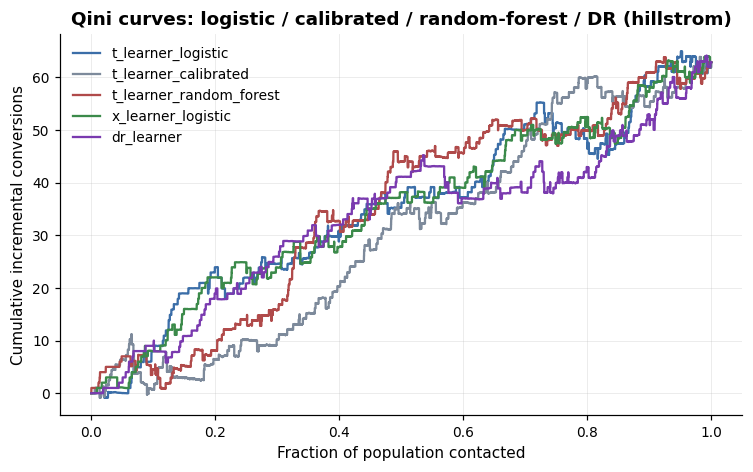

In [4]:
fig, ax = plt.subplots()
colors = {
    "t_learner_logistic": "#3b6ea8",
    "t_learner_calibrated": "#7d8a9b",
    "t_learner_random_forest": "#b04a4a",
    "x_learner_logistic": "#3b8a4a",
    "dr_learner": "#7a3aaf",
}
for name, scores in preds.items():
    curve = qini_curve(
        outcome=y_te.to_numpy(),
        treatment=t_te.to_numpy(),
        uplift_score=scores.to_numpy(),
    )
    ax.plot(
        curve["population_fraction"],
        curve["incremental_gain"],
        label=name,
        color=colors[name],
    )
ax.set_xlabel("Fraction of population contacted")
ax.set_ylabel("Cumulative incremental conversions")
ax.set_title(f"Qini curves: logistic / calibrated / random-forest / DR ({dataset.source})")
ax.legend()
save_figure(fig, "08_qini_overlay")
plt.show()

## 3. Ranking agreement

If two models agree on the ranking (high Spearman correlation), they will produce the same campaign at any fixed budget. If they disagree, the choice between them is a real policy choice and not a tuning detail.

In [5]:
names = list(preds.columns)
rho = pd.DataFrame(
    [
        [spearmanr(preds[a], preds[b]).correlation for b in names]
        for a in names
    ],
    index=names,
    columns=names,
).round(3)
rho

,t_learner_logistic,t_learner_calibrated,t_learner_random_forest,x_learner_logistic,dr_learner
t_learner_logistic,1.000,0.515,0.526,0.995,0.685
t_learner_calibrated,0.515,1.000,0.400,0.530,-0.096
t_learner_random_forest,0.526,0.400,1.000,0.530,0.266
x_learner_logistic,0.995,0.530,0.530,1.000,0.657
dr_learner,0.685,-0.096,0.266,0.657,1.000


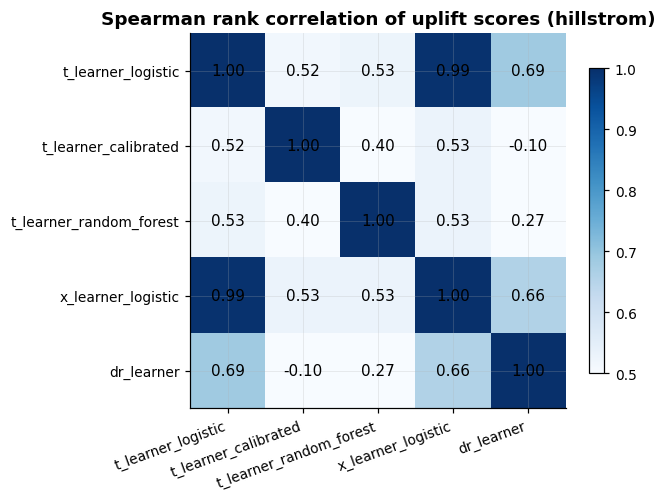

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(rho.to_numpy(), cmap="Blues", vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=20, ha="right")
ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", color="black")
ax.set_title(f"Spearman rank correlation of uplift scores ({dataset.source})")
fig.colorbar(im, ax=ax, shrink=0.8)
save_figure(fig, "08_ranking_agreement")
plt.show()

## 4. Takeaway

- The black-box T-learner can move AUQ relative to the logistic baseline; whether the move is positive or negative depends on the data and the regularisation regime.
- **Calibration vs. discrimination is a real trade-off.** Wrapping the base classifier in `make_calibrated_classifier` brings predicted absolute uplift much closer to the truth (notebook 06 closes the predicted-vs-realised profit gap by orders of magnitude) but can *lower* the AUQ slightly, because isotonic regression introduces ties in the score. Use the calibrated wrapper for *quoting* expected profit; use the uncalibrated ranker if AUQ is what you optimise for.
- The DR-learner sits in the same AUQ neighbourhood as T/X on randomized data but its absolute uplift levels are typically closer to the ATE — useful when downstream code consumes uplift values directly rather than just their ranking.
- Pairwise Spearman correlations imply that for most realistic budget cut-offs the *campaign* would not change much; the choice between models is a question of explainability, calibration, and operations rather than headline lift.
- For a campaign team that needs to defend the policy, prefer the simpler model when the Qini gap is small; reach for the black box (or for DR/calibration) when the gap is large *and* survives a robustness check.
